# Collaborative Filtering — Thử Nghiệm & Phân Tích

**IT Job Market Intelligence Platform**

Notebook này thực hiện thử nghiệm toàn bộ pipeline **Lọc Cộng Tác (Collaborative Filtering)**:

| Module | Mô tả |
|--------|-------|
| **Dữ liệu tương tác** | 800 ứng viên tổng hợp × ~22k sự kiện tương tác |
| **Item-to-Item CF** | Cosine Similarity trên ma trận User-Item |
| **Matrix Factorization** | TruncatedSVD 30 chiều tiềm ẩn |
| **Persona CF** | Điểm tương thích cộng đồng theo 8 nhóm chuyên môn IT |

---

## 0. Thiết lập môi trường

In [3]:
import os, sys

# Đưa project root vào sys.path
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print("Project root:", PROJECT_ROOT)

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Blues_d')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

print("Import thanh cong!")

Project root: c:\Users\Minh Doan\repo_github\IT-Job-Market-Intelligence
Import thanh cong!


## 1. Nạp & Khám Phá Dữ Liệu Tương Tác

In [4]:
INTERACTIONS_CSV = os.path.join(PROJECT_ROOT, "data", "interactions", "user_interactions.csv")
METADATA_JSON    = os.path.join(PROJECT_ROOT, "data", "interactions", "users_metadata.json")

# Nạp dữ liệu tương tác
# Cột thực tế: user_id, job_id, action, rating, affinity_score, timestamp
df = pd.read_csv(INTERACTIONS_CSV)
print(f"Columns: {list(df.columns)}")
print(f"Tong su kien tuong tac : {len(df):,}")
print(f"So ung vien tong hop   : {df['user_id'].nunique():,}")
print(f"So job_id xuat hien    : {df['job_id'].nunique():,}")
print(f"\nCac loai hanh vi (action):")
print(df['action'].value_counts())
df.head(10)

Columns: ['user_id', 'job_id', 'action', 'rating', 'affinity_score', 'timestamp']
Tong su kien tuong tac : 22,053
So ung vien tong hop   : 800
So job_id xuat hien    : 883

Cac loai hanh vi (action):
action
bookmark    10260
view         9928
apply        1865
Name: count, dtype: int64


,user_id,job_id,action,rating,affinity_score,timestamp
0,1,828,bookmark,2.0000,0.4500,2026-08-23 14:28:46
1,1,864,apply,3.0000,0.6220,2026-09-13 07:51:04
2,1,1763,bookmark,2.0000,0.5130,2026-08-17 22:23:43
3,1,2261,bookmark,2.0000,0.5130,2026-10-05 03:21:16
4,1,1430,bookmark,2.0000,0.5170,2026-09-17 17:52:27
5,1,108,bookmark,2.0000,0.4420,2026-09-18 15:45:41
6,1,714,bookmark,2.0000,0.4420,2026-10-06 14:03:49
7,1,2184,view,1.0000,0.5170,2026-09-25 06:48:36
8,1,837,view,1.0000,0.6220,2026-09-22 11:59:45
9,1,862,bookmark,2.0000,0.4420,2026-10-13 18:48:03


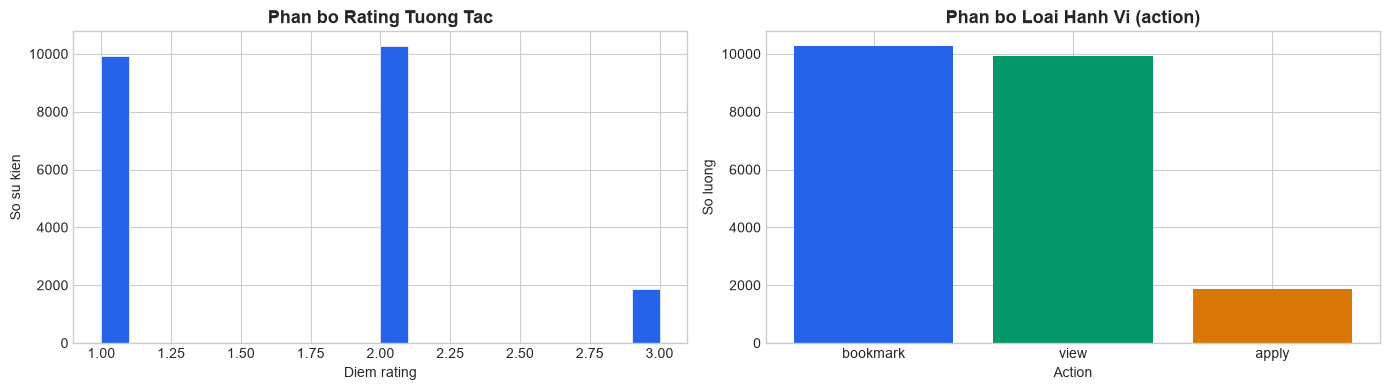

In [5]:
# Phân bố điểm tương tác (rating) và loại hành vi (action)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df['rating'], bins=20, color='#2563eb', edgecolor='white', linewidth=0.5)
axes[0].set_title('Phan bo Rating Tuong Tac', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Diem rating')
axes[0].set_ylabel('So su kien')

action_counts = df['action'].value_counts()
axes[1].bar(action_counts.index, action_counts.values, color=['#2563eb','#059669','#d97706','#dc2626'])
axes[1].set_title('Phan bo Loai Hanh Vi (action)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Action')
axes[1].set_ylabel('So luong')

plt.tight_layout()
plt.show()

Columns: ['user_id', 'persona_id', 'persona_name', 'seniority', 'city', 'skills']
So ung vien trong metadata: 800

Phan bo Persona:
persona_id
backend_java             144
frontend_react           128
fullstack_node_python    120
data_engineer             96
mobile_dev                80
ai_ml_engineer            80
fresher_intern            80
devops_cloud              72
Name: count, dtype: int64


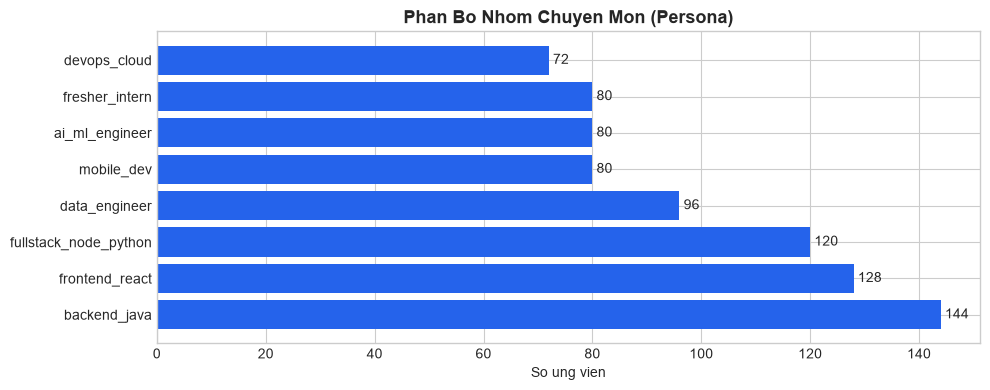

In [6]:
# Nạp metadata ứng viên (persona distribution)
import json
with open(METADATA_JSON, 'r', encoding='utf-8') as f:
    users_meta = json.load(f)

meta_df = pd.DataFrame(users_meta)
print(f"Columns: {list(meta_df.columns)}")
print(f"So ung vien trong metadata: {len(meta_df):,}")

# Cột thực tế: user_id, persona_id, persona_name, seniority, city, skills
persona_dist = meta_df['persona_id'].value_counts()
print("\nPhan bo Persona:")
print(persona_dist)

# Vẽ biểu đồ persona
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(persona_dist.index, persona_dist.values, color='#2563eb')
ax.bar_label(bars, fmt='%d', padding=3)
ax.set_title('Phan Bo Nhom Chuyen Mon (Persona)', fontsize=13, fontweight='bold')
ax.set_xlabel('So ung vien')
plt.tight_layout()
plt.show()

## 2. Xây Dựng Ma Trận User-Item

In [7]:
# Tổng hợp rating theo (user_id, job_id) — lấy max rating nếu nhiều lần tương tác
df_agg = df.groupby(['user_id', 'job_id'])['rating'].max().reset_index()

# Mapping index
users  = df_agg['user_id'].unique()
jobs   = df_agg['job_id'].unique()
user_to_idx = {u: i for i, u in enumerate(users)}
job_to_idx  = {j: i for i, j in enumerate(jobs)}
idx_to_job  = {i: j for j, i in job_to_idx.items()}

n_users = len(users)
n_jobs  = len(jobs)
print(f"Ma tran User-Item: {n_users} x {n_jobs}")

# Xây dựng ma trận thưa (Sparse CSR)
rows = df_agg['user_id'].map(user_to_idx).values
cols = df_agg['job_id'].map(job_to_idx).values
data = df_agg['rating'].values.astype(np.float32)

R = sp.csr_matrix((data, (rows, cols)), shape=(n_users, n_jobs))
density = R.nnz / (n_users * n_jobs) * 100
print(f"So phan tu != 0 : {R.nnz:,}")
print(f"Mat do ma tran  : {density:.4f}%  (Data Sparsity cao - binh thuong voi CF)")

Ma tran User-Item: 800 x 883
So phan tu != 0 : 22,053
Mat do ma tran  : 3.1219%  (Data Sparsity cao - binh thuong voi CF)


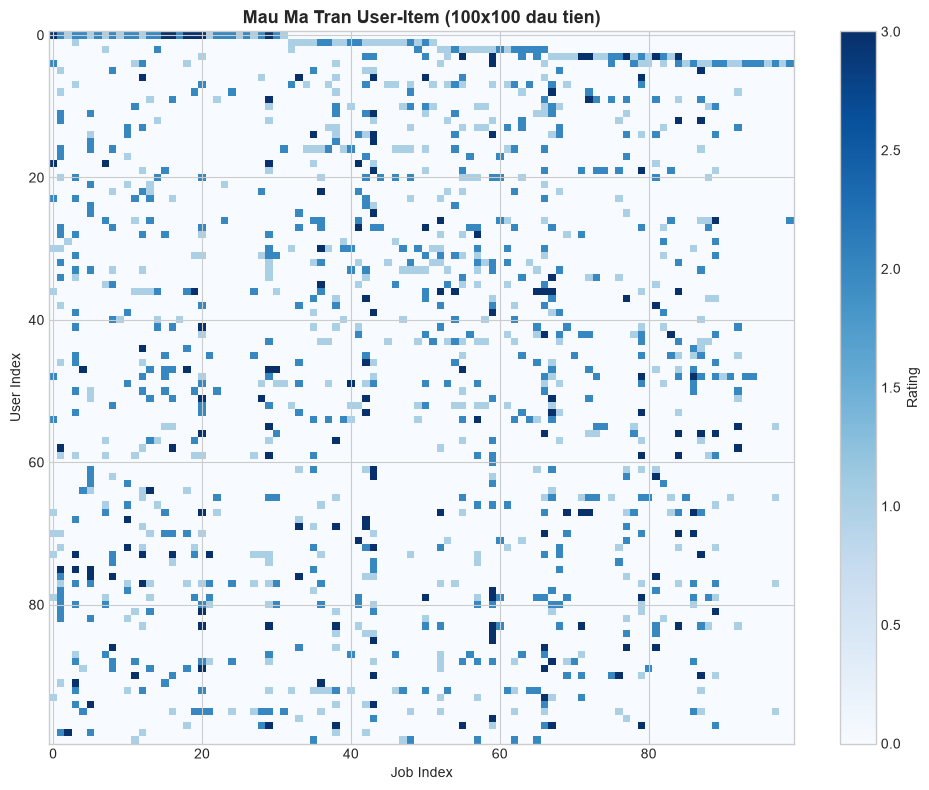

In [8]:
# Trực quan hóa mẫu 100x100 đầu tiên
sample = R[:100, :100].toarray()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(sample, aspect='auto', cmap='Blues', interpolation='nearest')
plt.colorbar(im, ax=ax, label='Rating')
ax.set_title('Mau Ma Tran User-Item (100x100 dau tien)', fontsize=13, fontweight='bold')
ax.set_xlabel('Job Index')
ax.set_ylabel('User Index')
plt.tight_layout()
plt.show()

## 3. Item-to-Item Collaborative Filtering

In [9]:
# Tính ma trận tương đồng Item-to-Item (Cosine Similarity)
# Transpose: mỗi hàng là 1 item, mỗi cột là 1 user
R_item = R.T.toarray()  # shape: (n_jobs, n_users)

print("Dang tinh Item-to-Item Cosine Similarity...")
item_sim = cosine_similarity(R_item)  # shape: (n_jobs, n_jobs)
print(f"Ma tran tuong dong: {item_sim.shape}")
print(f"Min: {item_sim.min():.4f}  Max: {item_sim.max():.4f}  Mean: {item_sim.mean():.4f}")

Dang tinh Item-to-Item Cosine Similarity...
Ma tran tuong dong: (883, 883)
Min: 0.0000  Max: 1.0000  Mean: 0.0239


In [10]:
# Kiểm tra Similar Jobs cho 1 công việc mẫu
def get_similar_jobs_manual(job_id: int, top_k: int = 5):
    """Tìm top_k công việc tương tự job_id bằng Item-to-Item CF."""
    if job_id not in job_to_idx:
        return []
    j_idx = job_to_idx[job_id]
    sims  = item_sim[j_idx].copy()
    sims[j_idx] = -1  # Loại bỏ chính nó
    top_indices = np.argsort(sims)[::-1][:top_k]
    return [(idx_to_job[i], round(float(sims[i]), 4)) for i in top_indices]

# Thử với job_id đầu tiên trong tập
sample_job_id = int(jobs[0])
print(f"Tim Similar Jobs cho job_id = {sample_job_id}:")
similar = get_similar_jobs_manual(sample_job_id, top_k=5)
for rank, (jid, score) in enumerate(similar, 1):
    print(f"  Top {rank}: job_id={jid}  similarity={score:.4f}")

Tim Similar Jobs cho job_id = 41:
  Top 1: job_id=344  similarity=0.2890
  Top 2: job_id=847  similarity=0.2859
  Top 3: job_id=42  similarity=0.2847
  Top 4: job_id=13  similarity=0.2595
  Top 5: job_id=503  similarity=0.2466


So cap item pair: 389,403


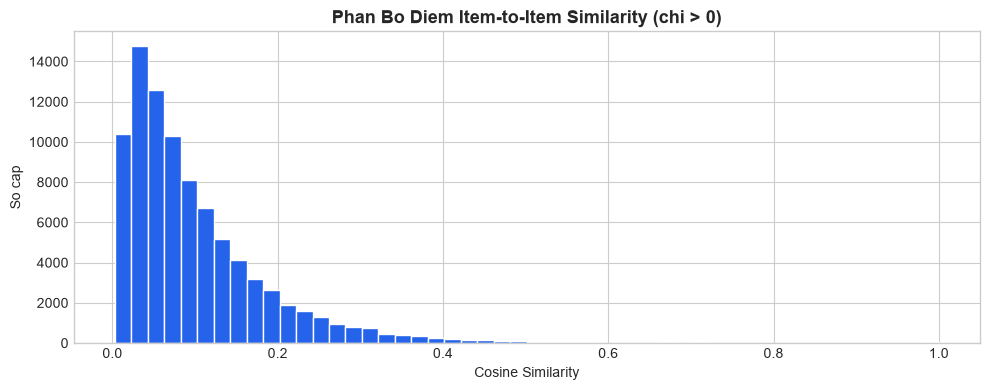

In [11]:
# Phân bố điểm tương đồng
sim_flat = item_sim[np.triu_indices(len(jobs), k=1)]
print(f"So cap item pair: {len(sim_flat):,}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(sim_flat[sim_flat > 0], bins=50, color='#2563eb', edgecolor='white')
ax.set_title('Phan Bo Diem Item-to-Item Similarity (chi > 0)', fontsize=13, fontweight='bold')
ax.set_xlabel('Cosine Similarity')
ax.set_ylabel('So cap')
plt.tight_layout()
plt.show()

## 4. Matrix Factorization với TruncatedSVD

In [12]:
# Chia train / test (80/20) để đánh giá
n_total = len(df_agg)
n_train = int(n_total * 0.8)

df_shuffled = df_agg.sample(frac=1, random_state=42).reset_index(drop=True)
df_train = df_shuffled[:n_train]
df_test  = df_shuffled[n_train:]

print(f"Train set: {len(df_train):,} su kien")
print(f"Test set : {len(df_test):,} su kien")

# Xây ma trận train
rows_tr = df_train['user_id'].map(user_to_idx).values
cols_tr = df_train['job_id'].map(job_to_idx).values
data_tr = df_train['rating'].values.astype(np.float32)

R_train = sp.csr_matrix((data_tr, (rows_tr, cols_tr)), shape=(n_users, n_jobs))

Train set: 17,642 su kien
Test set : 4,411 su kien


Thuc nghiem so chieu tiem an SVD:
  n_components= 10 -> Explained Variance: 16.92%
  n_components= 20 -> Explained Variance: 25.29%
  n_components= 30 -> Explained Variance: 31.96%
  n_components= 50 -> Explained Variance: 42.86%
  n_components= 80 -> Explained Variance: 55.14%


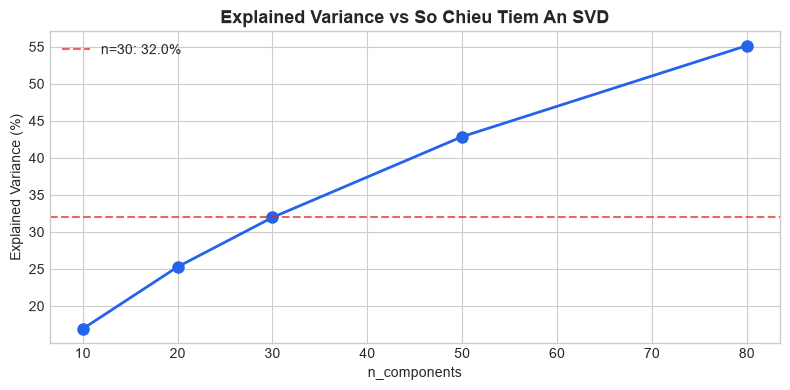

In [13]:
# Huấn luyện TruncatedSVD với nhiều giá trị n_components khác nhau
components_list = [10, 20, 30, 50, 80]
explained_vars  = []

print("Thuc nghiem so chieu tiem an SVD:")
for nc in components_list:
    svd = TruncatedSVD(n_components=nc, random_state=42)
    user_fac = svd.fit_transform(R_train)
    explained = svd.explained_variance_ratio_.sum()
    explained_vars.append(explained)
    print(f"  n_components={nc:3d} -> Explained Variance: {explained*100:.2f}%")

# Vẽ đường cong Explained Variance
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(components_list, [v*100 for v in explained_vars], 'o-', color='#2563eb', linewidth=2, markersize=8)
ax.axhline(y=explained_vars[2]*100, color='#dc2626', linestyle='--', alpha=0.7, label=f'n=30: {explained_vars[2]*100:.1f}%')
ax.set_title('Explained Variance vs So Chieu Tiem An SVD', fontsize=13, fontweight='bold')
ax.set_xlabel('n_components')
ax.set_ylabel('Explained Variance (%)')
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
# Huấn luyện SVD với n=30 (lựa chọn tốt nhất theo đồ thị)
N_COMPONENTS = 30
svd_model   = TruncatedSVD(n_components=N_COMPONENTS, random_state=42)
user_factors = svd_model.fit_transform(R_train)           # (n_users, n_components)
item_factors = svd_model.components_.T                    # (n_jobs, n_components)

print(f"User factors shape: {user_factors.shape}")
print(f"Item factors shape: {item_factors.shape}")
print(f"Explained variance: {svd_model.explained_variance_ratio_.sum()*100:.2f}%")

User factors shape: (800, 30)
Item factors shape: (883, 30)
Explained variance: 31.96%


In [15]:
# Đánh giá trên tập Test: RMSE & MAE
def predict_rating(user_id: int, job_id: int) -> float:
    if user_id not in user_to_idx or job_id not in job_to_idx:
        return 3.0  # fallback
    u_vec = user_factors[user_to_idx[user_id]]
    j_vec = item_factors[job_to_idx[job_id]]
    return float(np.dot(u_vec, j_vec))

y_true, y_pred = [], []
for _, row in df_test.iterrows():
    uid, jid, r_true = int(row['user_id']), int(row['job_id']), float(row['rating'])
    r_pred = predict_rating(uid, jid)
    y_true.append(r_true)
    y_pred.append(r_pred)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
mae  = np.mean(np.abs(y_true - y_pred))

print(f"Ket qua danh gia TruncatedSVD (n_components={N_COMPONENTS}):")
print(f"   RMSE: {rmse:.4f}")
print(f"   MAE : {mae:.4f}")

Ket qua danh gia TruncatedSVD (n_components=30):
   RMSE: 1.5390
   MAE : 1.3917


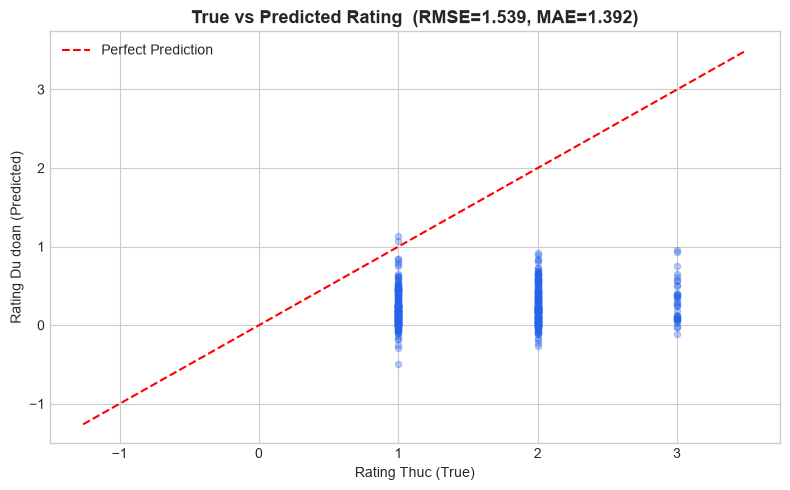

In [16]:
# Biểu đồ True vs Predicted
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(y_true[:500], y_pred[:500], alpha=0.3, color='#2563eb', s=20)
lims = [min(y_true.min(), y_pred.min()) - 0.5, max(y_true.max(), y_pred.max()) + 0.5]
ax.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect Prediction')
ax.set_xlabel('Rating Thuc (True)')
ax.set_ylabel('Rating Du doan (Predicted)')
ax.set_title(f'True vs Predicted Rating  (RMSE={rmse:.3f}, MAE={mae:.3f})', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

## 5. Persona Collaborative Filtering

In [17]:
from src.recommender.synthetic_data import PERSONAS_DEF
from src.recommender.collaborative import get_cf_recommender

# Nạp CF recommender đã lưu (hoặc train nếu chưa có)
print("Dang nap CollaborativeRecommender...")
cf_rec = get_cf_recommender()
print("Nap thanh cong!")
print(f"So personas: {len(PERSONAS_DEF)}")
for p in PERSONAS_DEF:
    print(f"  [{p['id']}] {p['name']}")

c:\Users\Minh Doan\repo_github\IT-Job-Market-Intelligence\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dang nap CollaborativeRecommender...
-> Nap thanh cong Collaborative Filtering Model (883 jobs).
Nap thanh cong!
So personas: 8
  [backend_java] Kỹ Sư Backend (Java / Microservices)
  [frontend_react] Kỹ Sư Frontend (React / TypeScript)
  [fullstack_node_python] Kỹ Sư Fullstack (Node.js / Python / Cloud)
  [mobile_dev] Lập Trình Viên Di Động (Flutter / iOS / Android)
  [data_engineer] Kỹ Sư Dữ Liệu & Phân Tích (Data Platform / SQL)
  [ai_ml_engineer] Kỹ Sư AI & Machine Learning (PyTorch / NLP / LLM)
  [devops_cloud] Kỹ Sư DevOps & Điện Toán Đám Mây (K8s / AWS)
  [fresher_intern] Thực Tập Sinh & Sinh Viên IT Mới Tốt Nghiệp


c:\Users\Minh Doan\repo_github\IT-Job-Market-Intelligence\src\recommender\collaborative.py:80: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


In [18]:
# Điểm CF cho từng persona
persona_score_stats = []

for p in PERSONAS_DEF:
    pid = p['id']
    scores = cf_rec.get_persona_scores_dict(pid)
    vals   = list(scores.values())
    persona_score_stats.append({
        'persona_id': pid,
        'name': p['name'][:30],
        'n_jobs_scored': len(vals),
        'mean_score': round(np.mean(vals), 4),
        'min_score': round(np.min(vals), 4),
        'max_score': round(np.max(vals), 4),
    })

stats_df = pd.DataFrame(persona_score_stats)
print("\nThong ke diem CF theo Persona:")
display(stats_df)


Thong ke diem CF theo Persona:


,persona_id,name,n_jobs_scored,mean_score,min_score,max_score
0,backend_java,Kỹ Sư Backend (Java / Microser,883,0.6521,0.6486,0.6839
1,frontend_react,Kỹ Sư Frontend (React / TypeSc,883,0.6518,0.6470,0.6796
2,fullstack_node_python,Kỹ Sư Fullstack (Node.js / Pyt,883,0.6522,0.6490,0.6782
3,mobile_dev,Lập Trình Viên Di Động (Flutte,883,0.6517,0.6451,0.7044
4,data_engineer,Kỹ Sư Dữ Liệu & Phân Tích (Dat,883,0.6520,0.6475,0.6758
5,ai_ml_engineer,Kỹ Sư AI & Machine Learning (P,883,0.6519,0.6470,0.6944
6,devops_cloud,Kỹ Sư DevOps & Điện Toán Đám M,883,0.6522,0.6471,0.6979
7,fresher_intern,Thực Tập Sinh & Sinh Viên IT M,883,0.6520,0.6483,0.6915


In [19]:
# Top 10 việc làm được CF gợi ý cho persona backend_java
# Lưu ý: get_recommendations_for_persona trả về keys:
#   job_id, title, company_name, city, seniority, work_mode, salary_str, skills, match_score
TOP_PERSONA = "backend_java"
top_jobs_cf = cf_rec.get_recommendations_for_persona(persona_id=TOP_PERSONA, top_n=10)

print(f"Top 10 viec lam CF cho persona '{TOP_PERSONA}':")
if top_jobs_cf:
    # Dùng đúng tên cột từ API: company_name, seniority, match_score
    cf_df = pd.DataFrame(top_jobs_cf)[['job_id', 'title', 'company_name', 'city', 'seniority', 'match_score']]
    cf_df.columns = ['job_id', 'title', 'company', 'city', 'seniority', 'cf_score']
    display(cf_df)
else:
    print("Chua co ket qua (can ket noi PostgreSQL).")

Top 10 viec lam CF cho persona 'backend_java':


,job_id,title,company,city,seniority,cf_score
0,809,Technical Lead,CHỨNG KHOÁN VPBANK,Hà Nội,Lead,73.4000
1,2401,Trưởng Nhóm Java Developer,Công nghệ Phần mềm Tinh Vân,Hà Nội,Lead,72.9000
2,726,Trưởng Nhóm Java,Công nghệ Phần mềm Tinh Vân,Hà Nội,Lead,72.8000
3,2498,Trưởng Nhóm Java,CÔNG NGHỆ ALPHAWAY,Hà Nội,Lead,72.8000
4,1916,Senior DevOps Engineer – Large-Scale Cloud-Nat...,THƯƠNG MẠI DỊCH VỤ VEXERE,Hồ Chí Minh,Senior,72.5000
5,108,Backend Developer,ĐẦU TƯ QUỐC TẾ DGLOBAL,Hà Nội,Undetermined,72.5000
6,2348,Senior Backend Developer,VIỄN THÔNG VIETTEL-CHI NHÁNH TẬP ĐOÀN CÔNG NGH...,Hà Nội,Senior,72.3000
7,1558,Senior Backend Developer,MỘT THÀNH VIÊN AN NINH MẠNG VIETTEL,Hà Nội,Senior,72.2000
8,837,"FullStack Developer (Junior, Senior) - Khối Cô...",MBBANK,Hà Nội,Senior,72.2000
9,2760,Senior Java Engineer,GIMO,Hà Nội,Senior,72.2000


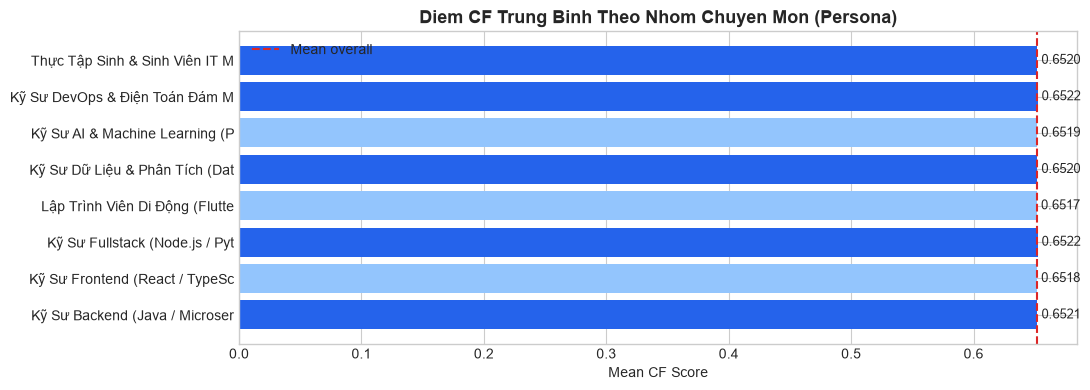

In [20]:
# So sánh điểm CF trung bình giữa các Persona
fig, ax = plt.subplots(figsize=(11, 4))
colors = ['#2563eb' if s > stats_df['mean_score'].mean() else '#93c5fd' for s in stats_df['mean_score']]
bars = ax.barh(stats_df['name'], stats_df['mean_score'], color=colors)
ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=9)
ax.axvline(stats_df['mean_score'].mean(), color='#dc2626', linestyle='--', label='Mean overall')
ax.set_title('Diem CF Trung Binh Theo Nhom Chuyen Mon (Persona)', fontsize=13, fontweight='bold')
ax.set_xlabel('Mean CF Score')
ax.legend()
plt.tight_layout()
plt.show()

## 6. Kiểm Tra Module CollaborativeRecommender Tích Hợp

In [21]:
# Similar Jobs — People Also Applied
# Lưu ý: get_similar_jobs trả về keys:
#   job_id, title, company_name, city, seniority, work_mode, salary_str, skills, similarity_pct
cf = get_cf_recommender()

# Lấy job_id mẫu từ dữ liệu tương tác (job được tương tác nhiều nhất)
sample_jid = int(df['job_id'].value_counts().index[0])
print(f"Tim Similar Jobs cho job_id = {sample_jid} (job duoc tuong tac nhieu nhat):")

similar_jobs = cf.get_similar_jobs(job_id=sample_jid, top_k=5)
if similar_jobs:
    for r, j in enumerate(similar_jobs, 1):
        # Dùng đúng tên key: job_id (không phải similar_job_id), similarity_pct (không phải similarity_score)
        print(f"  #{r}  job_id={j.get('job_id', '?')}  score={j.get('similarity_pct', 0):.1f}%  [{j.get('title','?')}]")
else:
    print("  Can ket noi DB de truy xuat metadata.")

Tim Similar Jobs cho job_id = 7 (job duoc tuong tac nhieu nhat):
  #1  job_id=784  score=50.0%  [AI DEVELOPER – JUNIOR/MIDDLE]
  #2  job_id=304  score=50.0%  [Junior Frontend Engineer (Shopify)]
  #3  job_id=1841  score=50.0%  [Junior Data Engineer]
  #4  job_id=253  score=50.0%  [Full Stack Developer Junior]
  #5  job_id=123  score=50.0%  [Junior Fullstack Software Engineer (Tại Quang Trung -Hà Đông)]


In [22]:
# Hiển thị dạng bảng cho similar jobs
if similar_jobs:
    sim_df = pd.DataFrame(similar_jobs)[['job_id', 'title', 'company_name', 'city', 'seniority', 'similarity_pct']]
    display(sim_df)

,job_id,title,company_name,city,seniority,similarity_pct
0,784,AI DEVELOPER – JUNIOR/MIDDLE,SUNTEK,Hồ Chí Minh,Junior,50.0000
1,304,Junior Frontend Engineer (Shopify),CÔNG NGHỆ LAZYCY,Hà Nội,Junior,50.0000
2,1841,Junior Data Engineer,Điện Toán Group,Hồ Chí Minh,Junior,50.0000
3,253,Full Stack Developer Junior,SonatGame Studio,Hà Nội,Junior,50.0000
4,123,Junior Fullstack Software Engineer (Tại Quang ...,ĐẦU TƯ THƯƠNG MẠI TBESTPRO,Hà Nội,Junior,50.0000


## 7. Tổng Kết

In [23]:
print("=" * 60)
print("TONG KET THUC NGHIEM COLLABORATIVE FILTERING")
print("=" * 60)
print(f"\n[Du lieu]")
print(f"  So ung vien      : {n_users:,}")
print(f"  So viec lam CF   : {n_jobs:,}")
print(f"  So su kien       : {len(df):,}")
print(f"  Mat do ma tran   : {density:.4f}%")

print(f"\n[Item-to-Item CF]")
nonzero_pairs = np.sum(sim_flat > 0)
print(f"  Cap similarity > 0: {nonzero_pairs:,} / {len(sim_flat):,}")

print(f"\n[TruncatedSVD - Matrix Factorization]")
print(f"  n_components         : {N_COMPONENTS}")
print(f"  Explained variance   : {svd_model.explained_variance_ratio_.sum()*100:.2f}%")
print(f"  Test RMSE            : {rmse:.4f}")
print(f"  Test MAE             : {mae:.4f}")

print(f"\n[Personas]")
for _, row in stats_df.iterrows():
    print(f"  {row['persona_id']:20s} -> mean_score={row['mean_score']:.4f}  max={row['max_score']:.4f}")

print("\nCF Pipeline hoan chinh va san sang tich hop vao True Hybrid!")

TONG KET THUC NGHIEM COLLABORATIVE FILTERING

[Du lieu]
  So ung vien      : 800
  So viec lam CF   : 883
  So su kien       : 22,053
  Mat do ma tran   : 3.1219%

[Item-to-Item CF]
  Cap similarity > 0: 87,893 / 389,403

[TruncatedSVD - Matrix Factorization]
  n_components         : 30
  Explained variance   : 31.96%
  Test RMSE            : 1.5390
  Test MAE             : 1.3917

[Personas]
  backend_java         -> mean_score=0.6521  max=0.6839
  frontend_react       -> mean_score=0.6518  max=0.6796
  fullstack_node_python -> mean_score=0.6522  max=0.6782
  mobile_dev           -> mean_score=0.6517  max=0.7044
  data_engineer        -> mean_score=0.6520  max=0.6758
  ai_ml_engineer       -> mean_score=0.6519  max=0.6944
  devops_cloud         -> mean_score=0.6522  max=0.6979
  fresher_intern       -> mean_score=0.6520  max=0.6915

CF Pipeline hoan chinh va san sang tich hop vao True Hybrid!
